In [92]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants

#BENUTZT DATEN VON 30.06 & 02.07 aber die sind schrott

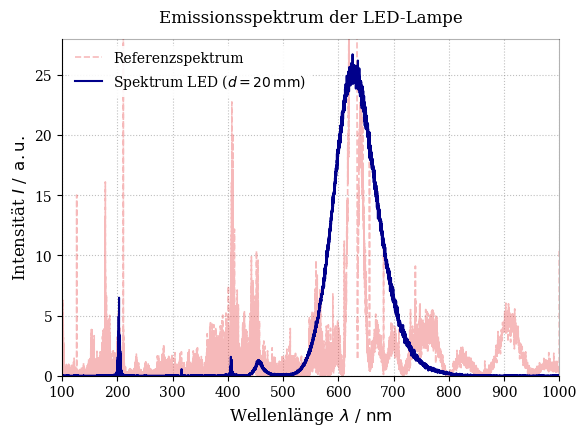

In [93]:

led20 = np.genfromtxt(
    'Spektrum_led_20mm.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

led20_ref = np.genfromtxt(
    'Spektrum_led_20mm_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge = led20[:,0]
amplitude = led20[:,1]
wellenlänge_ref = led20_ref[:,0]
amplitude_ref = led20_ref[:,1]

mask = amplitude < 30

amplitude = amplitude[mask]

wellenlänge = wellenlänge[mask]

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

# Erstellung der Figur im typischen einspaltigen Paper-Format (ca. 8.5 cm Breite)
fig, ax = plt.subplots(figsize=(6, 4.5))
#fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)

# Plots zeichnen
# Referenz zuerst, damit die Hauptmessung physisch darüber liegt
ax.plot(wellenlänge_ref, amplitude_ref, 
        color='#e41a1c', alpha=0.3, lw=1.2, ls='--', 
        label='Referenzspektrum')

ax.plot(wellenlänge, amplitude, 
        color='darkblue', lw=1.5, 
        label='Spektrum LED ($d = 20\,\mathrm{mm}$)')

# —————————————————————————————————————————————————————————————————————————————
# 3. ACHSEN, TITEL & LEGENDE
# —————————————————————————————————————————————————————————————————————————————
# Präzise Achsenbeschriftung mit korrekten physikalischen Einheiten in LaTeX
ax.set_xlabel(r'Wellenlänge $\lambda$ / $\mathrm{nm}$')
ax.set_ylabel(r'Intensität $I$ / $\,\mathrm{a.u.}$')
ax.set_title('Emissionsspektrum der LED-Lampe', pad=12)

# Grenzen exakt wie vorgegeben (angepasst an die Skalierung / 1000)
ax.set_xlim(100, 1000)
ax.set_ylim(0,28)

# Dezentes, professionelles Grid
ax.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)

# Rahmen (Spines) oben und rechts sichtbar lassen, aber dezent (Standard im Physik-Paper)
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['top'].set_alpha(0.3)
ax.spines['right'].set_alpha(0.3)

# Legende ohne störenden dicken Rahmen, leicht transparent platziert
ax.legend(loc='upper left', frameon=True, framealpha=0.9, edgecolor='none')

# Layout optimieren und speichern
plt.tight_layout()
fig.savefig('LED_Spektrum_d20mm.pdf', bbox_inches='tight') # Vektorgrafik für LaTeX-Dokumente

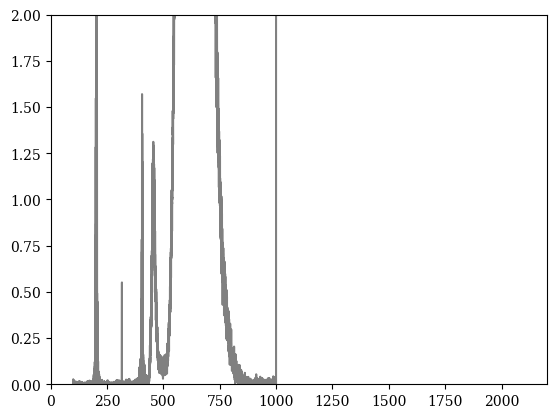

In [94]:

# 1. Konstanten definieren
h = constants.h           # Plancksches Wirkungsquantum
c = constants.c           # Lichtgeschwindigkeit
k_B = constants.k  

led20 = np.genfromtxt(
    'Spektrum_led_20mm.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

led20_ref = np.genfromtxt(
    'Spektrum_led_20mm_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge = led20[:,0]
amplitude = led20[:,1]
wellenlänge_ref = led20_ref[:,0]
amplitude_ref = led20_ref[:,1]

glüh = np.genfromtxt(
    'Spektrum-glüh.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_glüh = glüh[:,0]
wellenzahl_glüh=1e7/wellenlänge_glüh
amplitude_glüh = glüh[:,1]

ausreisser_maske = (wellenlänge_glüh < 4900) | (wellenlänge_glüh > 5100)

wellenlänge_glüh_clean = wellenlänge_glüh[ausreisser_maske]
amplitude_glüh_clean = amplitude_glüh[ausreisser_maske]

plt.plot(wellenlänge, amplitude, color='grey', label='LED 20mm')
#plt.plot(wellenlänge_ref, amplitude_ref, color='red', label='LED 20mm Ref', alpha=0.1)
#plt.plot(wellenlänge_glüh_clean, amplitude_glüh_clean/np.max(amplitude_glüh_clean), color='orange', label='glüh 20mm')
plt.xlim(0, 2200)
plt.ylim(0, 2)
plt.show()

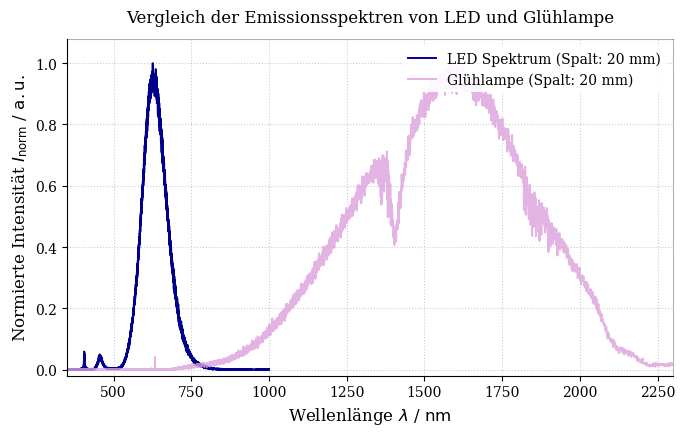

In [95]:
import numpy as np
import matplotlib.pyplot as plt
import os

# —————————————————————————————————————————————————————————————————————————————
# GLOBALE SCHRIFT- UND LAYOUT-KONFIGURATION (Veröffentlichungsstandard)
# —————————————————————————————————————————————————————————————————————————————
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

# —————————————————————————————————————————————————————————————————————————————
# 1. LED-DATEN EINLESEN & BEREINIGEN
# —————————————————————————————————————————————————————————————————————————————

led20 = np.genfromtxt(
    'Spektrum_led_20mm.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

led20_ref = np.genfromtxt(
    'Spektrum_led_20mm_ref.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

# Rohdaten extrahieren
wellenlänge_raw = led20[:, 0]
amplitude_raw = led20[:, 1]
wellenlänge_ref_raw = led20_ref[:, 0]
amplitude_ref_raw = led20_ref[:, 1]

# Ausreißer entfernen (y > 30 filtern)
mask_led = amplitude_raw <= 30
wellenlänge_led = wellenlänge_raw[mask_led]
amplitude_led = amplitude_raw[mask_led]

mask_ref = amplitude_ref_raw <= 30
wellenlänge_ref = wellenlänge_ref_raw[mask_ref]
amplitude_ref = amplitude_ref_raw[mask_ref]

# —————————————————————————————————————————————————————————————————————————————
# 2. GLÜHLAMPEN-DATEN EINLESEN & BEREINIGEN
# —————————————————————————————————————————————————————————————————————————————

glüh = np.genfromtxt(
    'Spektrum-glüh.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenlänge_glüh = glüh[:, 0]
amplitude_glüh = glüh[:, 1]

# Ausreißer entfernen (Bereich um 5000)
ausreisser_maske = (wellenlänge_glüh < 4900) | (wellenlänge_glüh > 5100)
wellenlänge_glüh_clean = wellenlänge_glüh[ausreisser_maske]
amplitude_glüh_clean = amplitude_glüh[ausreisser_maske]

# —————————————————————————————————————————————————————————————————————————————
# 3. PROFESSIONELLER PLOT
# —————————————————————————————————————————————————————————————————————————————
fig, ax = plt.subplots(figsize=(7, 4.5))

# Daten normiert plotten mit akademischer Farbpalette
ax.plot(wellenlänge_led, amplitude_led / np.max(amplitude_led), 
        color='darkblue', lw=1.4, label='LED Spektrum (Spalt: 20 mm)')

#ax.plot(wellenlänge_ref, amplitude_ref / np.max(amplitude_ref), 
        #color='#e41a1c', lw=1.1, ls='--', alpha=0.4, label='LED Referenzspektrum')

ax.plot(wellenlänge_glüh_clean, amplitude_glüh_clean / np.max(amplitude_glüh_clean), 
        color='plum', lw=1.4, alpha=0.8, label='Glühlampe (Spalt: 20 mm)')

# Achsen-Konfiguration (Präzise LaTeX-Formate)
ax.set_xlabel(r'Wellenlänge $\lambda$ / $\mathrm{nm}$')
ax.set_ylabel(r'Normierte Intensität $I_{\mathrm{norm}}$ / $\mathrm{a.u.}$')
ax.set_title('Vergleich der Emissionsspektren von LED und Glühlampe', pad=12)

# Grenzen & Achsen-Styling
ax.set_xlim(350, 2300) # Startet ab 350, da davor meist nur Null-Rauschen ist
ax.set_ylim(-0.02, 1.08)

# Dezentes, professionelles Grid
ax.grid(True, which='both', linestyle=':', color='gray', alpha=0.4)

# Dezenter Rahmen (Spines oben und rechts teiltransparent)
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['top'].set_alpha(0.3)
ax.spines['right'].set_alpha(0.3)

# Legende ohne störenden Kastenrahmen
ax.legend(loc='upper right', frameon=True, framealpha=0.9, edgecolor='none')

plt.tight_layout()

# Direkter Export als hochauflösendes PNG für LaTeX/Beamer
plt.savefig('Emissionsspektren_Vergleich_LED_Glüh.pdf', bbox_inches='tight')
plt.show()